# Test of Discretization Algorithms

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi

import plotly.io as pio
pio.renderers.default = 'notebook_connected' # 'browser' for avoid error but shown in the browser
import plotly.graph_objects as go

# import surpRISe
from surpRISe.utils.utils import *
from surpRISe.components.ris import RIS
from surpRISe.components.antenna import Antenna
from surpRISe.channels.tx2ris2rx.tang_ff_channel import tang_ff_channel
from surpRISe.channels.tx2ris2rx.tang_general_channel import tang_general_channel

In [2]:
# Create Objects
f = 28e9
lam = c/f

ris = RIS(name="RIS",center=[0,0,0],boresight='z',Ncol=128,Nrow=128,delta_h=lam/2,delta_v=lam/2,dx=0.47*lam,dy=0.47*lam,fc=f,radiation_factor=1,phase_shifts_dict={"0": 0,"1": pi},att_dict={"0": 1,"1": 1})

tx_pos = sph2cart([5,0,0])
tx_antenna = Antenna(tx_pos,0)

rx_pos = sph2cart([5,180,30])
rx_antenna = Antenna(rx_pos,0)

ch = tang_general_channel()



--- Testing optimization algorithm: direct_disc
Optimizer 'discrete direct_disc': Optimizing time 0.0068 sec.
Final Normalized BF Gain with direct_disc: 0.4056

--- Testing optimization algorithm: chen_alg1
Optimizer 'discrete chen_alg1': Optimizing time 0.0086 sec.
Final Normalized BF Gain with chen_alg1: 0.4049

--- Testing optimization algorithm: grid_search
Optimum value of α: 1.260 rad
Optimizer 'discrete grid_search': Optimizing time 0.4663 sec.
Plotting Grid Search Landscape...


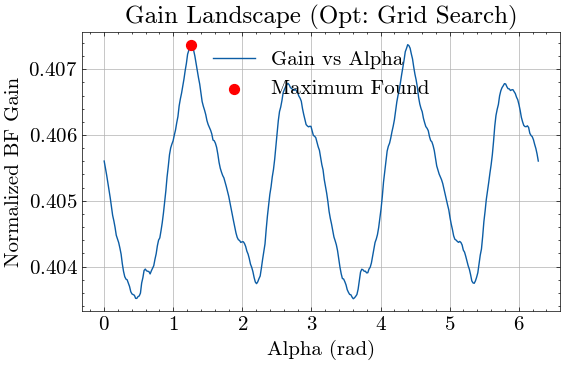

Final Normalized BF Gain with grid_search: 0.4074

--- Testing optimization algorithm: iterative
Iterative solution converged in 32 iterations.
Optimum value of α found: -0.106 rad
Optimizer 'discrete iterative': Optimizing time 0.0452 sec.
Plotting Iterative Convergence...


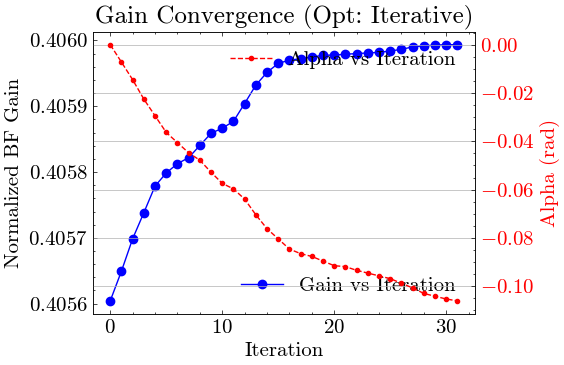

Final Normalized BF Gain with iterative: 0.4060

--- Summary of Beamforming Gains:
Algorithm: direct_disc     | BF Gain: 0.4056
Algorithm: chen_alg1       | BF Gain: 0.4049
Algorithm: grid_search     | BF Gain: 0.4074
Algorithm: iterative       | BF Gain: 0.4060


In [3]:
# Test different algorithms
# algorithms = ['direct_disc', 'chen_alg1', 'grid_search', '1d_search', 'iterative']
algorithms = ['direct_disc', 'chen_alg1', 'grid_search', 'iterative']
verbose = True
bf_list = []

max_bf = (ris.Nrow * ris.Ncol) ** 2

for alg in algorithms:
    print(f"\n--- Testing optimization algorithm: {alg}")
    ris.reset_ris()
    ch.optimize(optimizer = alg, mode = 'disc', wave_model = 'spherical', tx_antenna = tx_antenna, rx_antenna = rx_antenna, ris = ris, verbose = verbose)
    # ris.plot_phase_dist()
    bf = ch.phase_bf_multrx(tx_antenna = tx_antenna, rx_positions = rx_pos, ris = ris)
    bf_gain = bf[0] / max_bf
    print(f"Final Normalized BF Gain with {alg}: {bf_gain:.4f}")
    
    bf_list.append((alg, bf_gain))
    
# Summary of results
print("\n--- Summary of Beamforming Gains:")
    
res_str = "\n".join(f"Algorithm: {alg:15s} | BF Gain: {gain:.4f}" for alg, gain in bf_list)
print(res_str)